In [ ]:
import os, time, random, json, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

import torch
import torchvision
from torchvision.datasets import CIFAR10
from torchvision import transforms
from torchvision.models import resnet50, ResNet50_Weights

from sklearn.metrics import confusion_matrix, classification_report, accuracy_score
from sklearn.preprocessing import normalize
from skimage.feature import hog

warnings.filterwarnings("ignore")

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
OUTPUT_DIR = Path("/content/cbir_outputs")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("PyTorch:", torch.__version__)
print("Torchvision:", torchvision.__version__)
print("Çalışma aygıtı:", DEVICE)
print("Çıktı klasörü:", OUTPUT_DIR)

PyTorch: 2.11.0+cu130
Torchvision: 0.26.0+cu130
Çalışma aygıtı: cuda
Çıktı klasörü: /content/cbir_outputs


In [ ]:
DATA_ROOT = "/content/data"

train_ds = CIFAR10(root=DATA_ROOT, train=True, download=True)
test_ds  = CIFAR10(root=DATA_ROOT, train=False, download=True)

CLASS_NAMES = train_ds.classes
print("Sınıflar:", CLASS_NAMES)
print("Eğitim görüntüsü:", len(train_ds))
print("Test görüntüsü:", len(test_ds))

100%|██████████| 170M/170M [29:22<00:00, 96.7kB/s]


Sınıflar: ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']
Eğitim görüntüsü: 50000
Test görüntüsü: 10000


,Sınıf,Eğitim,Test
0,airplane,5000,1000
1,automobile,5000,1000
2,bird,5000,1000
3,cat,5000,1000
4,deer,5000,1000
5,dog,5000,1000
6,frog,5000,1000
7,horse,5000,1000
8,ship,5000,1000
9,truck,5000,1000


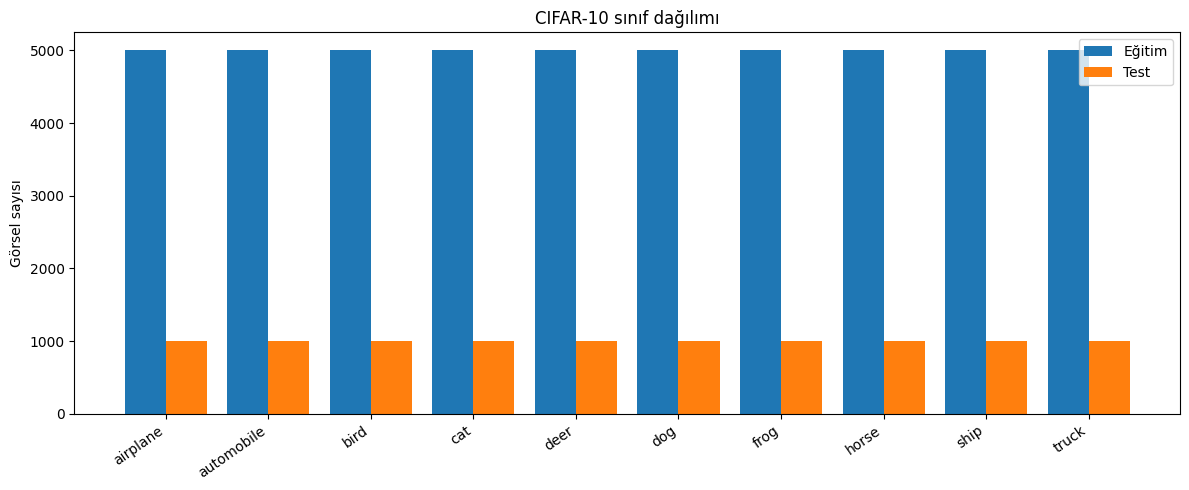

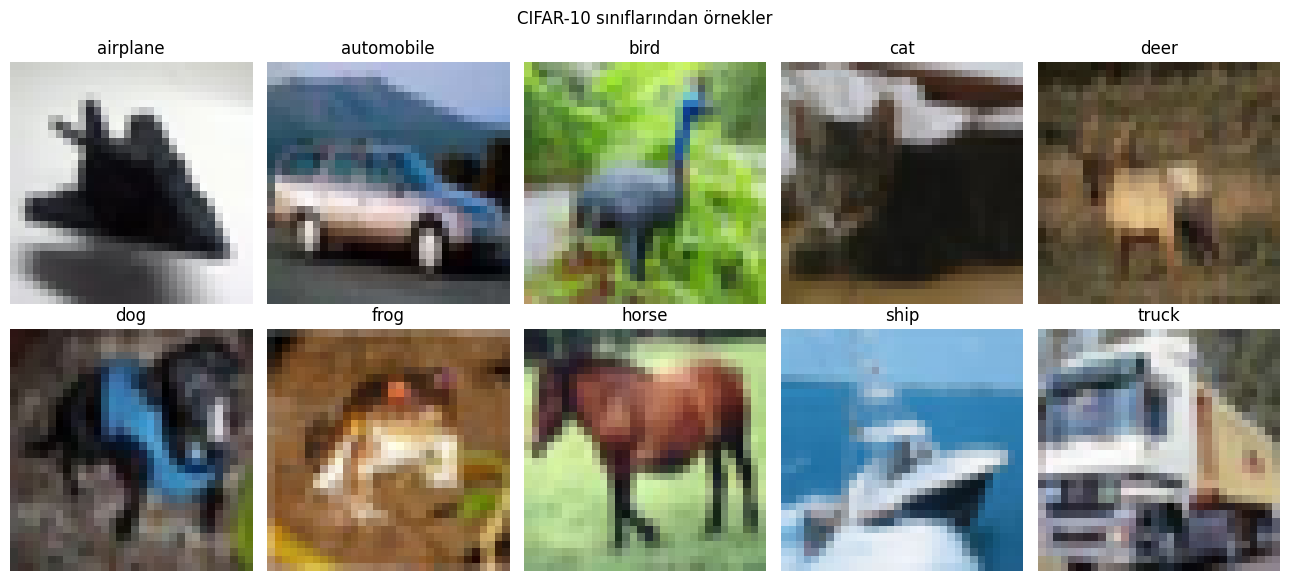

In [ ]:
def dataset_labels(ds):
    # torchvision CIFAR10 labels listesi
    return np.asarray(ds.targets, dtype=np.int64)

train_labels = dataset_labels(train_ds)
test_labels = dataset_labels(test_ds)

counts = pd.DataFrame({
    "Sınıf": CLASS_NAMES,
    "Eğitim": np.bincount(train_labels, minlength=10),
    "Test": np.bincount(test_labels, minlength=10)
})
display(counts)
counts.to_csv(OUTPUT_DIR / "sinif_dagilimi.csv", index=False)

plt.figure(figsize=(12, 5))
x = np.arange(10)
plt.bar(x - 0.2, counts["Eğitim"], width=0.4, label="Eğitim")
plt.bar(x + 0.2, counts["Test"], width=0.4, label="Test")
plt.xticks(x, CLASS_NAMES, rotation=35, ha="right")
plt.ylabel("Görsel sayısı")
plt.title("CIFAR-10 sınıf dağılımı")
plt.legend()
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "01_sinif_dagilimi.png", dpi=160)
plt.show()

fig, axes = plt.subplots(2, 5, figsize=(13, 6))
for cls, ax in enumerate(axes.flat):
    idx = next(i for i, y in enumerate(train_labels) if y == cls)
    img, label = train_ds[idx]
    ax.imshow(img)
    ax.set_title(CLASS_NAMES[label])
    ax.axis("off")
plt.suptitle("CIFAR-10 sınıflarından örnekler")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "02_ornek_gorseller.png", dpi=160)
plt.show()

In [ ]:
class CIFARResized(torch.utils.data.Dataset):
    def __init__(self, base_dataset, indices, transform):
        self.base_dataset = base_dataset
        self.indices = list(map(int, indices))
        self.transform = transform

    def __len__(self):
        return len(self.indices)

    def __getitem__(self, i):
        image, label = self.base_dataset[self.indices[i]]
        return self.transform(image), int(label), int(self.indices[i])

# Eksik değişkenleri tanımlıyoruz
BATCH_SIZE = 128

# ResNet50 modelini ve transformasyonunu yüklüyoruz
weights = ResNet50_Weights.IMAGENET1K_V1
resnet_transform = weights.transforms()

feature_extractor = resnet50(weights=weights)
feature_extractor.fc = torch.nn.Identity() # Sınıflandırma katmanını at
feature_extractor = feature_extractor.to(DEVICE).eval()

# Veritabanı ve sorgu için tüm indeksleri kullanıyoruz
db_indices = np.arange(len(train_ds))
query_indices = np.arange(len(test_ds))

@torch.inference_mode()
def extract_resnet_features(base_dataset, indices, batch_size=BATCH_SIZE):
    ds = CIFARResized(base_dataset, indices, resnet_transform)
    loader = torch.utils.data.DataLoader(
        ds, batch_size=batch_size, shuffle=False,
        num_workers=2 if os.name != "nt" else 0,
        pin_memory=(DEVICE.type == "cuda")
    )
    all_features, all_labels, all_indices = [], [], []
    start = time.perf_counter()
    for batch_x, batch_y, batch_idx in loader:
        batch_x = batch_x.to(DEVICE)
        feats = feature_extractor(batch_x).flatten(1)
        all_features.append(feats.cpu().numpy().astype(np.float32))
        all_labels.append(batch_y.numpy())
        all_indices.append(batch_idx.numpy())
    elapsed = time.perf_counter() - start
    return (
        np.concatenate(all_features),
        np.concatenate(all_labels),
        np.concatenate(all_indices),
        elapsed
    )

db_features, db_y, db_original_indices, db_extract_seconds = extract_resnet_features(train_ds, db_indices)
query_features, query_y, query_original_indices, query_extract_seconds = extract_resnet_features(test_ds, query_indices)

print("Veritabanı özellik matrisi:", db_features.shape)
print("Sorgu özellik matrisi:", query_features.shape)
print(f"Veritabanı özellik çıkarma süresi: {db_extract_seconds:.1f} sn")
print(f"Sorgu özellik çıkarma süresi: {query_extract_seconds:.1f} sn")
assert db_features.shape[1] == 2048, "ResNet50 özellik boyutu beklenenden farklı!"

Downloading: "https://download.pytorch.org/models/resnet50-0676ba61.pth" to /root/.cache/torch/hub/checkpoints/resnet50-0676ba61.pth


100%|██████████| 97.8M/97.8M [00:01<00:00, 78.5MB/s]


Veritabanı özellik matrisi: (50000, 2048)
Sorgu özellik matrisi: (10000, 2048)
Veritabanı özellik çıkarma süresi: 179.2 sn
Sorgu özellik çıkarma süresi: 39.4 sn


In [ ]:
np.save(OUTPUT_DIR / "resnet50_db_features.npy", db_features)
np.save(OUTPUT_DIR / "resnet50_query_features.npy", query_features)
np.save(OUTPUT_DIR / "db_labels.npy", db_y)
np.save(OUTPUT_DIR / "query_labels.npy", query_y)

feature_summary = pd.DataFrame({
    "Öğe": ["Veritabanı görüntüsü", "Sorgu görüntüsü", "Özellik boyutu",
            "Veritabanı çıkarım süresi (sn)", "Sorgu çıkarım süresi (sn)"],
    "Değer": [len(db_features), len(query_features), db_features.shape[1],
              round(db_extract_seconds, 3), round(query_extract_seconds, 3)]
})
display(feature_summary)
feature_summary.to_csv(OUTPUT_DIR / "ozellik_cikarim_ozeti.csv", index=False)

,Öğe,Değer
0,Veritabanı görüntüsü,50000.000
1,Sorgu görüntüsü,10000.000
2,Özellik boyutu,2048.000
3,Veritabanı çıkarım süresi (sn),179.193
4,Sorgu çıkarım süresi (sn),39.434


In [ ]:
def pairwise_distances(query_vec, database_matrix, metric="euclidean"):
    q = np.asarray(query_vec, dtype=np.float32).reshape(1, -1)
    X = np.asarray(database_matrix, dtype=np.float32)

    if metric == "euclidean":
        # ||x-y||^2 = ||x||^2 + ||y||^2 - 2 x.y
        d2 = np.sum(X * X, axis=1) + np.sum(q * q) - 2 * (X @ q.T).ravel()
        return np.sqrt(np.maximum(d2, 0))
    elif metric == "cosine":
        qn = q / (np.linalg.norm(q, axis=1, keepdims=True) + 1e-12)
        Xn = X / (np.linalg.norm(X, axis=1, keepdims=True) + 1e-12)
        return 1.0 - (Xn @ qn.T).ravel()
    elif metric == "manhattan":
        return np.abs(X - q).sum(axis=1)
    else:
        raise ValueError("Desteklenmeyen metrik: " + metric)

def retrieve(query_vec, database_features, database_labels, top_k=5, metric="euclidean"):
    distances = pairwise_distances(query_vec, database_features, metric=metric)
    # Eşit uzaklıklarda sonuçlar deterministik olsun diye argsort kullanılır.
    order = np.argsort(distances)[:top_k]
    return order, distances[order]

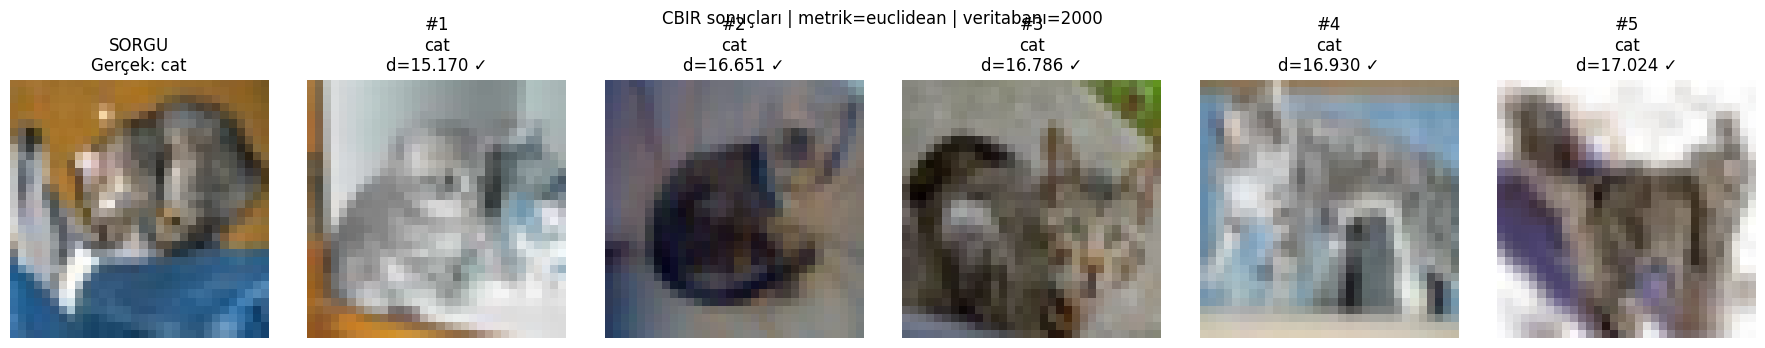

In [ ]:
TOP_K = 5

def show_retrieval(query_position=0, top_k=TOP_K, metric="euclidean", db_size=None):
    if db_size is None:
        db_size = len(db_features)
    feats = db_features[:db_size]
    labels = db_y[:db_size]

    order, distances = retrieve(query_features[query_position], feats, labels, top_k, metric)
    query_img, query_label = test_ds[int(query_original_indices[query_position])]

    fig, axes = plt.subplots(1, top_k + 1, figsize=(3 * (top_k + 1), 3.5))
    axes[0].imshow(query_img)
    axes[0].set_title(f"SORGU\nGerçek: {CLASS_NAMES[query_y[query_position]]}")
    axes[0].axis("off")

    for rank, (db_pos, dist) in enumerate(zip(order, distances), start=1):
        img_idx = int(db_original_indices[db_pos])
        img, label = train_ds[img_idx]
        axes[rank].imshow(img)
        axes[rank].set_title(
            f"#{rank}\n{CLASS_NAMES[label]}\nd={dist:.3f}"
            + (" ✓" if label == query_y[query_position] else "")
        )
        axes[rank].axis("off")

    plt.suptitle(f"CBIR sonuçları | metrik={metric} | veritabanı={db_size}")
    plt.tight_layout()
    path = OUTPUT_DIR / f"ornek_sorgu_{query_position}_{metric}_{db_size}.png"
    plt.savefig(path, dpi=160)
    plt.show()

show_retrieval(query_position=0, top_k=TOP_K, metric="euclidean", db_size=min(2000, len(db_features)))

In [ ]:
def retrieval_metrics(retrieved_labels, query_label, database_labels, k):
    retrieved_labels = np.asarray(retrieved_labels[:k])
    relevant_total = int(np.sum(np.asarray(database_labels) == query_label))
    hits = (retrieved_labels == query_label).astype(np.float32)

    precision = float(hits.sum() / k)
    recall = float(hits.sum() / relevant_total) if relevant_total else 0.0
    f1 = 2 * precision * recall / (precision + recall) if precision + recall else 0.0

    # AP@K: sıralama boyunca precision@rank değerlerini doğru eşleşmelerde ortala.
    cumulative_precision = np.cumsum(hits) / np.arange(1, k + 1)
    ap = float((cumulative_precision * hits).sum() / min(relevant_total, k)) if min(relevant_total, k) else 0.0

    return precision, recall, f1, ap

In [ ]:
def evaluate_database_size(db_size, metric="euclidean", top_k=TOP_K):
    X = db_features[:db_size]
    y = db_y[:db_size]

    results = []
    for qi in range(len(query_features)):
        start_time = time.perf_counter()
        order, _ = retrieve(query_features[qi], X, y, top_k=top_k, metric=metric)
        query_time_ms = (time.perf_counter() - start_time) * 1000

        labels_k = y[order]
        p, r, f1, ap = retrieval_metrics(labels_k, query_y[qi], y, top_k)

        results.append({
            "metric": metric,
            "db_size": db_size,
            "query_idx": qi,
            "precision_at_k": p,
            "recall_at_k": r,
            "f1_at_k": f1,
            "ap_at_k": ap,
            "query_time_ms": query_time_ms
        })
    return pd.DataFrame(results)

METRICS = ["euclidean", "cosine", "manhattan"]
COMPARE_DB_SIZE = min(5000, len(db_features))
metric_results = []

for metric in METRICS:
    print("Metrik:", metric)
    metric_results.append(evaluate_database_size(COMPARE_DB_SIZE, metric=metric))

metric_detail = pd.concat(metric_results, ignore_index=True)
metric_summary = (metric_detail.groupby("metric", as_index=False)
                 .agg(Precision_at_K=("precision_at_k", "mean"),
                      Recall_at_K=("recall_at_k", "mean"),
                      F1_at_K=("f1_at_k", "mean"),
                      mAP_at_K=("ap_at_k", "mean"),
                      Ortalama_sorgu_suresi_ms=("query_time_ms", "mean")))
display(metric_summary.round(4))
metric_detail.to_csv(OUTPUT_DIR / "deney_B_metrik_sorgu_bazli.csv", index=False)
metric_summary.to_csv(OUTPUT_DIR / "deney_B_metrik_karsilastirma.csv", index=False)

Metrik: euclidean
Metrik: cosine
Metrik: manhattan


,metric,Precision_at_K,Recall_at_K,F1_at_K,mAP_at_K,Ortalama_sorgu_suresi_ms
0,cosine,0.7323,0.0073,0.0145,0.6762,24.3679
1,euclidean,0.7119,0.0071,0.0141,0.6517,15.5080
2,manhattan,0.7140,0.0072,0.0142,0.6542,17.8778


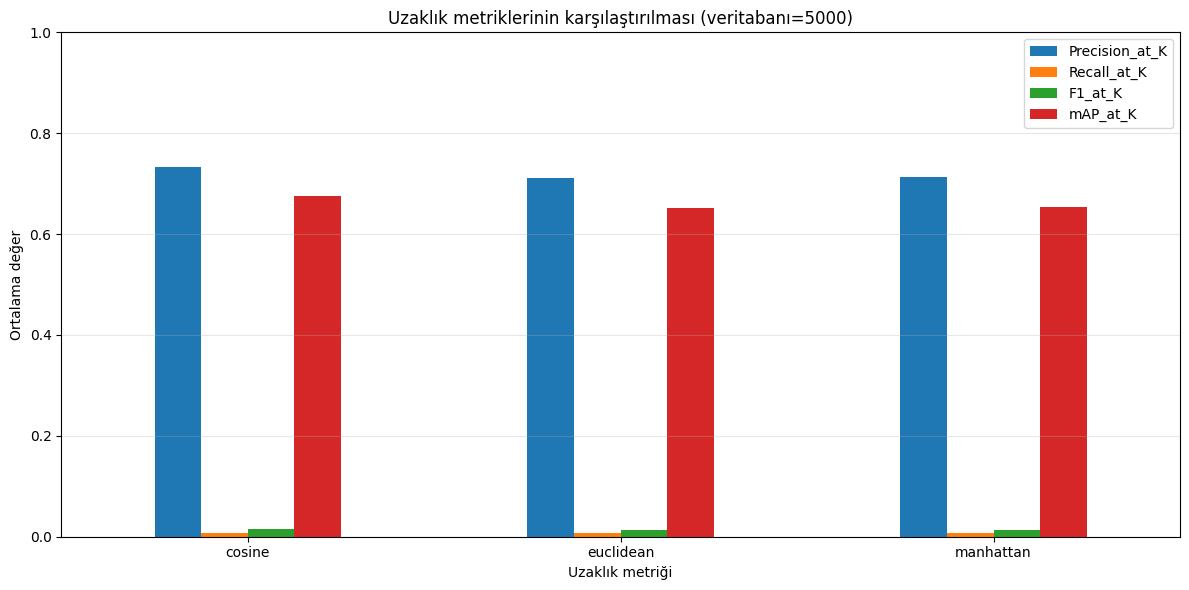

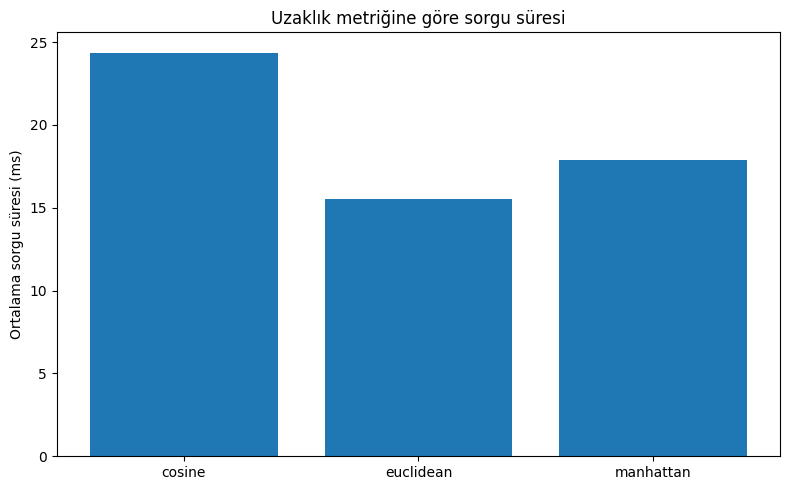

In [ ]:
plot_cols = ["Precision_at_K", "Recall_at_K", "F1_at_K", "mAP_at_K"]
ax = metric_summary.set_index("metric")[plot_cols].plot(kind="bar", figsize=(12, 6))
ax.set_title(f"Uzaklık metriklerinin karşılaştırılması (veritabanı={COMPARE_DB_SIZE})")
ax.set_ylabel("Ortalama değer")
ax.set_xlabel("Uzaklık metriği")
ax.set_ylim(0, 1)
ax.grid(axis="y", alpha=0.3)
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "05_uzaklik_metrikleri_basari.png", dpi=160)
plt.show()

plt.figure(figsize=(8, 5))
plt.bar(metric_summary["metric"], metric_summary["Ortalama_sorgu_suresi_ms"])
plt.ylabel("Ortalama sorgu süresi (ms)")
plt.title("Uzaklık metriğine göre sorgu süresi")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "06_uzaklik_metrikleri_sure.png", dpi=160)
plt.show()

Çoğunluk oylaması sınıf tahmini doğruluğu: 0.7948
              precision    recall  f1-score   support

    airplane     0.7951    0.8190    0.8069      1000
  automobile     0.8376    0.9130    0.8737      1000
        bird     0.8193    0.6800    0.7432      1000
         cat     0.6281    0.7110    0.6670      1000
        deer     0.6980    0.7880    0.7403      1000
         dog     0.8253    0.7040    0.7598      1000
        frog     0.8232    0.8100    0.8165      1000
       horse     0.8488    0.7520    0.7975      1000
        ship     0.8558    0.9020    0.8783      1000
       truck     0.8587    0.8690    0.8638      1000

    accuracy                         0.7948     10000
   macro avg     0.7990    0.7948    0.7947     10000
weighted avg     0.7990    0.7948    0.7947     10000



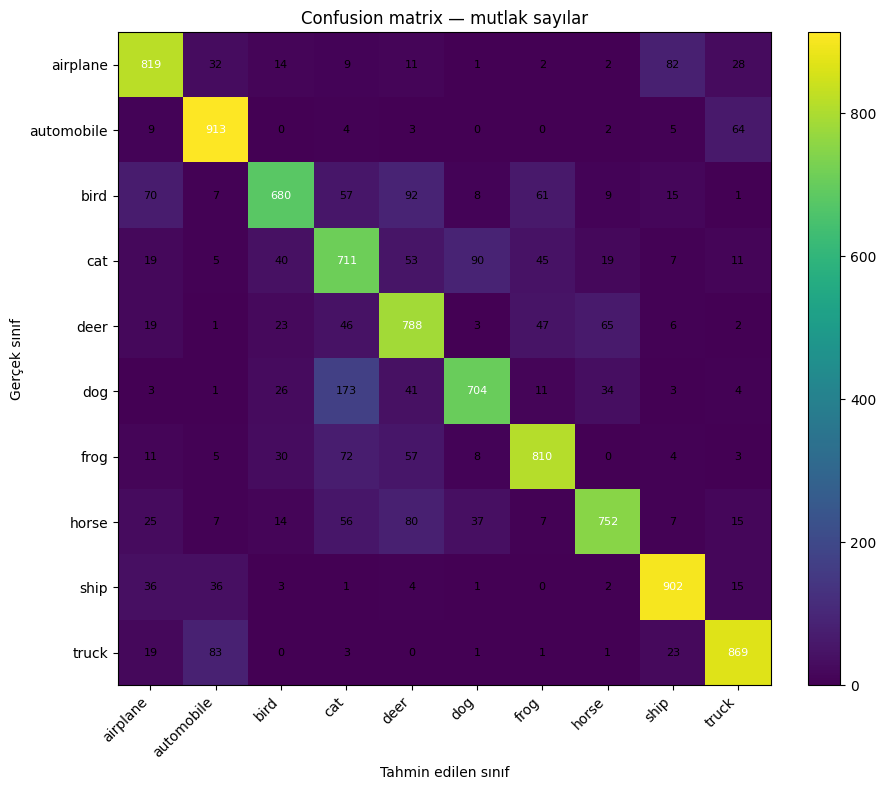

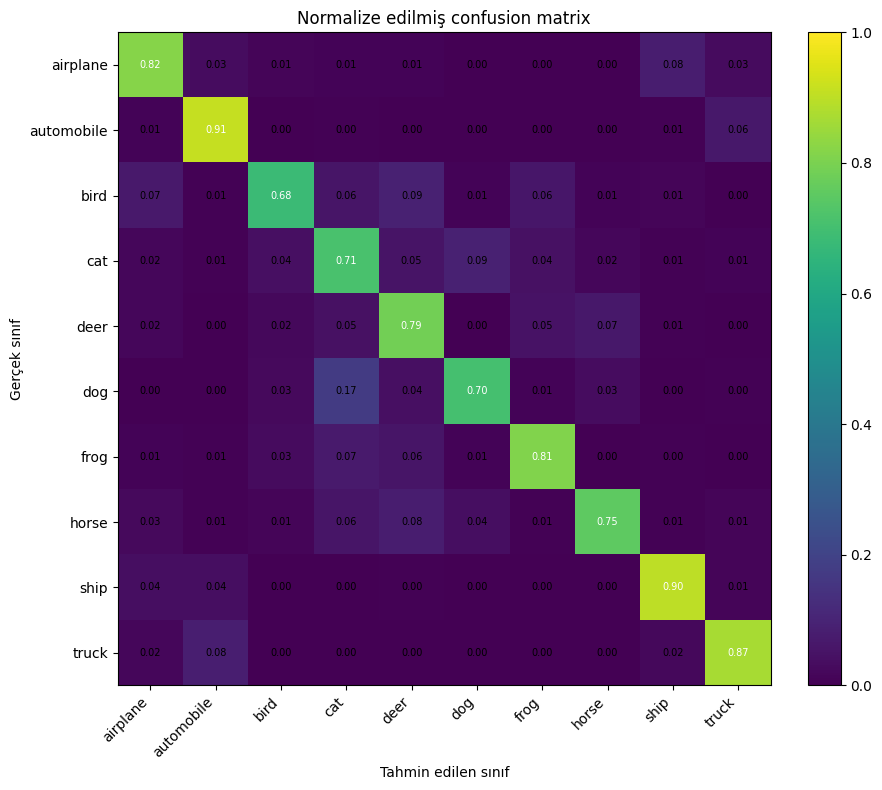

In [ ]:
def majority_vote_prediction(query_position, db_size, metric="euclidean", top_k=TOP_K):
    X, y = db_features[:db_size], db_y[:db_size]
    order, _ = retrieve(query_features[query_position], X, y, top_k=top_k, metric=metric)
    labels = y[order]
    counts = np.bincount(labels, minlength=len(CLASS_NAMES))
    # Eşitlik durumunda en küçük sınıf indeksi seçilir; sonuç deterministiktir.
    return int(np.argmax(counts))

CM_DB_SIZE = min(5000, len(db_features))
y_true = query_y.copy()
y_pred = np.array([
    majority_vote_prediction(i, CM_DB_SIZE, metric="euclidean", top_k=TOP_K)
    for i in range(len(query_features))
])

cm = confusion_matrix(y_true, y_pred, labels=np.arange(10))
cm_norm = confusion_matrix(y_true, y_pred, labels=np.arange(10), normalize="true")
cm_accuracy = accuracy_score(y_true, y_pred)

print(f"Çoğunluk oylaması sınıf tahmini doğruluğu: {cm_accuracy:.4f}")
print(classification_report(y_true, y_pred, labels=np.arange(10),
                            target_names=CLASS_NAMES, zero_division=0, digits=4))

fig, ax = plt.subplots(figsize=(10, 8))
im = ax.imshow(cm, interpolation="nearest")
ax.set_title("Confusion matrix — mutlak sayılar")
ax.set_xlabel("Tahmin edilen sınıf")
ax.set_ylabel("Gerçek sınıf")
ax.set_xticks(np.arange(10), labels=CLASS_NAMES, rotation=45, ha="right")
ax.set_yticks(np.arange(10), labels=CLASS_NAMES)
plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
threshold = cm.max() / 2 if cm.size else 0
for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        ax.text(j, i, str(cm[i, j]), ha="center", va="center",
                color="white" if cm[i, j] > threshold else "black", fontsize=8)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "07_confusion_matrix.png", dpi=180)
plt.show()

fig, ax = plt.subplots(figsize=(10, 8))
im = ax.imshow(cm_norm, vmin=0, vmax=1, interpolation="nearest")
ax.set_title("Normalize edilmiş confusion matrix")
ax.set_xlabel("Tahmin edilen sınıf")
ax.set_ylabel("Gerçek sınıf")
ax.set_xticks(np.arange(10), labels=CLASS_NAMES, rotation=45, ha="right")
ax.set_yticks(np.arange(10), labels=CLASS_NAMES)
plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
for i in range(cm_norm.shape[0]):
    for j in range(cm_norm.shape[1]):
        ax.text(j, i, f"{cm_norm[i, j]:.2f}", ha="center", va="center",
                color="white" if cm_norm[i, j] > 0.5 else "black", fontsize=7)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "08_confusion_matrix_normalize.png", dpi=180)
plt.show()

pd.DataFrame(cm, index=CLASS_NAMES, columns=CLASS_NAMES).to_csv(OUTPUT_DIR / "confusion_matrix.csv")
pd.DataFrame(cm_norm, index=CLASS_NAMES, columns=CLASS_NAMES).to_csv(OUTPUT_DIR / "confusion_matrix_normalize.csv")

### Sabit Veritabanında $K=5$ ve $K=10$ Sonuçlarının Görsel Karşılaştırması

Bu bölümde, veritabanı boyutunu sabit tutarak ($5000$ görsel), aynı sorgunun getirdiği sonuç kümesini genişlettiğimizde ($K=5$ ve $K=10$ durumlarında) görsel çıktıların ve eşleşme doğruluklarının nasıl değiştiğini doğrudan yan yana inceleyeceğiz.

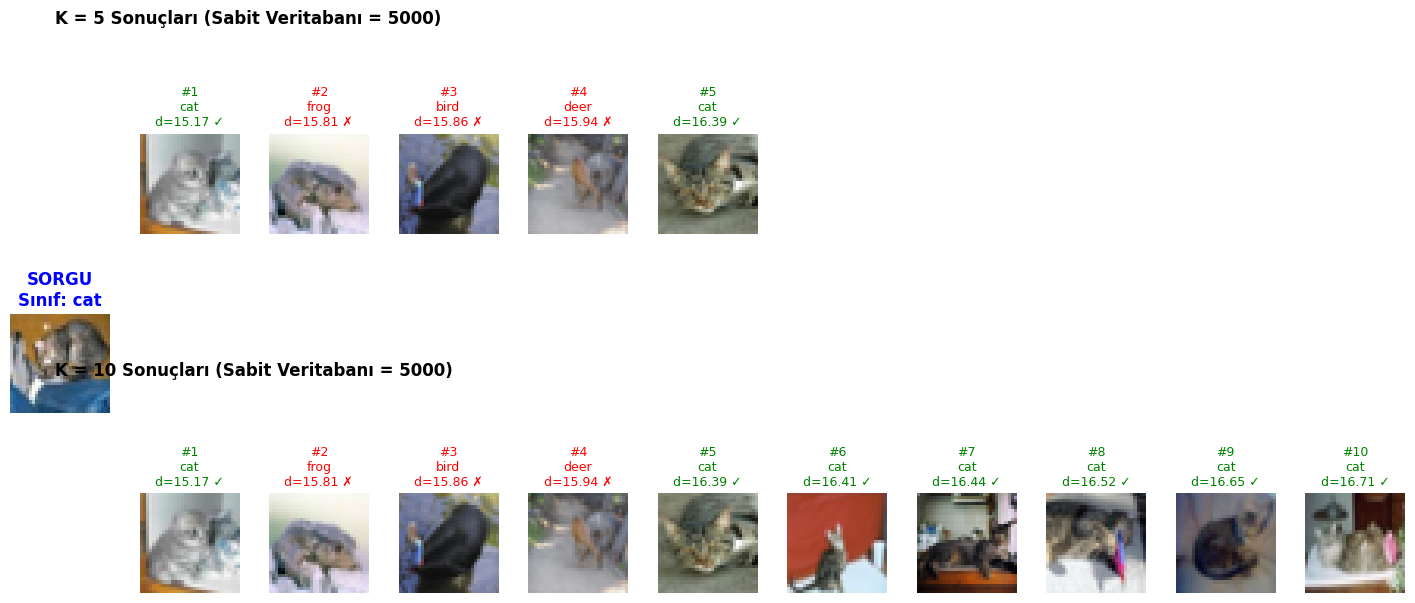

In [ ]:
def compare_k_visually(query_position=0, db_size=5000, metric="euclidean"):
    X = db_features[:db_size]
    labels = db_y[:db_size]

    # K=5 için sorgu
    order_5, dists_5 = retrieve(query_features[query_position], X, labels, top_k=5, metric=metric)
    # K=10 için sorgu
    order_10, dists_10 = retrieve(query_features[query_position], X, labels, top_k=10, metric=metric)

    query_img, query_label = test_ds[int(query_original_indices[query_position])]

    # Plotting
    fig = plt.figure(figsize=(18, 8))
    gs = fig.add_gridspec(2, 11, hspace=0.4, wspace=0.3)

    # Sol tarafa sorgu görselini koyuyoruz
    ax_q = fig.add_subplot(gs[:, 0])
    ax_q.imshow(query_img)
    ax_q.set_title(f"SORGU\nSınıf: {CLASS_NAMES[query_y[query_position]]}", fontweight='bold', color='blue')
    ax_q.axis("off")

    # Satır 1: K=5 sonuçları
    for rank, (db_pos, dist) in enumerate(zip(order_5, dists_5), start=1):
        ax = fig.add_subplot(gs[0, rank])
        img_idx = int(db_original_indices[db_pos])
        img, label = train_ds[img_idx]
        ax.imshow(img)
        is_correct = (label == query_y[query_position])
        ax.set_title(f"#{rank}\n{CLASS_NAMES[label]}\nd={dist:.2f}" + (" ✓" if is_correct else " ✗"),
                     color='green' if is_correct else 'red', fontsize=9)
        ax.axis("off")

    # K=5 boşluklarını doldur (boş kalan kolonları kapat)
    for rank in range(6, 11):
        ax = fig.add_subplot(gs[0, rank])
        ax.axis("off")

    # Satır 2: K=10 sonuçları
    for rank, (db_pos, dist) in enumerate(zip(order_10, dists_10), start=1):
        ax = fig.add_subplot(gs[1, rank])
        img_idx = int(db_original_indices[db_pos])
        img, label = train_ds[img_idx]
        ax.imshow(img)
        is_correct = (label == query_y[query_position])
        ax.set_title(f"#{rank}\n{CLASS_NAMES[label]}\nd={dist:.2f}" + (" ✓" if is_correct else " ✗"),
                     color='green' if is_correct else 'red', fontsize=9)
        ax.axis("off")

    fig.text(0.15, 0.92, f"K = 5 Sonuçları (Sabit Veritabanı = {db_size})", fontsize=12, fontweight='bold')
    fig.text(0.15, 0.48, f"K = 10 Sonuçları (Sabit Veritabanı = {db_size})", fontsize=12, fontweight='bold')

    plt.savefig(OUTPUT_DIR / f"k_karsilastirma_visual_{query_position}.png", dpi=160, bbox_inches='tight')
    plt.show()

# Örnek bir sorgu görseli (query_position=0) üzerinde K=5 ve K=10 karşılaştırması
compare_k_visually(query_position=0, db_size=5000)

### Sabit Veritabanında Değişen K Değerlerinin Metrikler ve Confusion Matrix Üzerindeki Etkisi

Bu bölümde veritabanı boyutunu sabit tutarak ($5000$ görsel), sadece sorgu sonuç sayısını ($K = 1, 3, 5, 10, 20, 50$) değiştiriyoruz. Her bir $K$ seviyesi için:
1. Arama başarım metriklerini (Precision, Recall, F1, mAP) hesaplayıp tabloluyoruz.
2. Getirilen komşuların çoğunluk oylamasına dayalı sınıf tahminlerini yapıp, her bir $K$ seviyesi için oluşan **Confusion Matrix** grafiklerini ve genel doğruluk oranlarını karşılaştırmalı olarak çizdiriyoruz.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, accuracy_score, classification_report

# Sabit veritabanı boyutu
EVAL_DB_SIZE = 5000
X_db = db_features[:EVAL_DB_SIZE]
y_db = db_y[:EVAL_DB_SIZE]
y_true = query_y.copy()

K_TEST_VALUES = [1, 3, 5, 10, 20, 50]

systematic_k_rows = []
confusion_matrices = {}
accuracies = {}

print(f"Sabit veritabanı ({EVAL_DB_SIZE} görsel) üzerinde değişen K değerleri için analiz başlatılıyor...")

# Tüm sorguların en yakın komşularını tek seferde en büyük K (50) için çekelim
max_k = max(K_TEST_VALUES)
all_retrieved_orders = []

for qi in range(len(query_features)):
    order, _ = retrieve(query_features[qi], X_db, y_db, top_k=max_k, metric="euclidean")
    all_retrieved_orders.append(order)

# Her K değeri için metrik hesaplama ve Sınıflandırma Karşılaştırması
for k in K_TEST_VALUES:
    p_list, r_list, f1_list, ap_list = [], [], [], []
    y_pred_k = []

    for qi in range(len(query_features)):
        order_k = all_retrieved_orders[qi][:k]
        labels_k = y_db[order_k]

        # Retrieval Metrikleri
        p, r, f1, ap = retrieval_metrics(labels_k, query_y[qi], y_db, k)
        p_list.append(p)
        r_list.append(r)
        f1_list.append(f1)
        ap_list.append(ap)

        # Çoğunluk oylaması tahmini
        counts = np.bincount(labels_k, minlength=10)
        y_pred_k.append(np.argmax(counts))

    y_pred_k = np.array(y_pred_k)
    acc = accuracy_score(y_true, y_pred_k)
    accuracies[k] = acc
    confusion_matrices[k] = confusion_matrix(y_true, y_pred_k, labels=np.arange(10))

    systematic_k_rows.append({
        "K": k,
        "Precision@K": np.mean(p_list),
        "Recall@K": np.mean(r_list),
        "F1@K": np.mean(f1_list),
        "mAP@K": np.mean(ap_list),
        "Majority_Vote_Accuracy": acc
    })

systematic_k_df = pd.DataFrame(systematic_k_rows)
display(systematic_k_df.round(4))
systematic_k_df.to_csv(OUTPUT_DIR / "sabit_db_degisen_k_analizi.csv", index=False)

Sabit veritabanı (5000 görsel) üzerinde değişen K değerleri için analiz başlatılıyor...


,K,Precision@K,Recall@K,F1@K,mAP@K,Majority_Vote_Accuracy
0,1,0.7541,0.0015,0.0030,0.7541,0.7541
1,3,0.7279,0.0044,0.0087,0.6865,0.7751
2,5,0.7119,0.0071,0.0141,0.6517,0.7948
3,10,0.6846,0.0137,0.0269,0.6017,0.8014
4,20,0.6548,0.0263,0.0505,0.5524,0.8008
5,50,0.6058,0.0608,0.1105,0.4819,0.7920


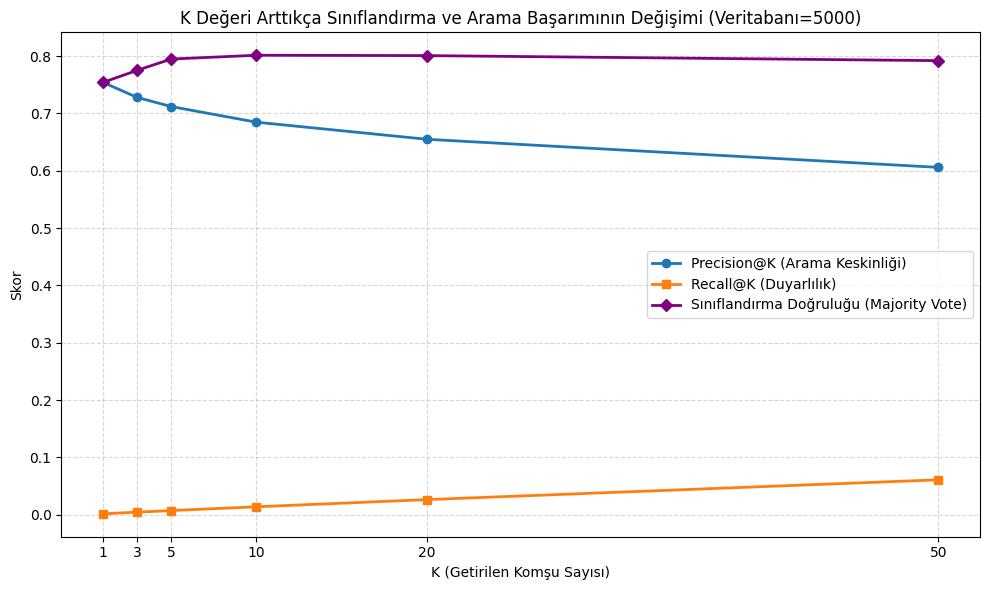

In [ ]:
# 1. Performans Metriklerinin K Değişimine Göre Grafiği
plt.figure(figsize=(10, 6))
plt.plot(systematic_k_df["K"], systematic_k_df["Precision@K"], marker="o", linewidth=2, label="Precision@K (Arama Keskinliği)")
plt.plot(systematic_k_df["K"], systematic_k_df["Recall@K"], marker="s", linewidth=2, label="Recall@K (Duyarlılık)")
plt.plot(systematic_k_df["K"], systematic_k_df["Majority_Vote_Accuracy"], marker="D", linewidth=2, color="purple", label="Sınıflandırma Doğruluğu (Majority Vote)")
plt.xlabel("K (Getirilen Komşu Sayısı)")
plt.ylabel("Skor")
plt.title(f"K Değeri Arttıkça Sınıflandırma ve Arama Başarımının Değişimi (Veritabanı={EVAL_DB_SIZE})")
plt.xticks(K_TEST_VALUES)
plt.grid(True, linestyle="--", alpha=0.5)
plt.legend()
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "sabit_db_k_degisimi_metrikler.png", dpi=160)
plt.show()

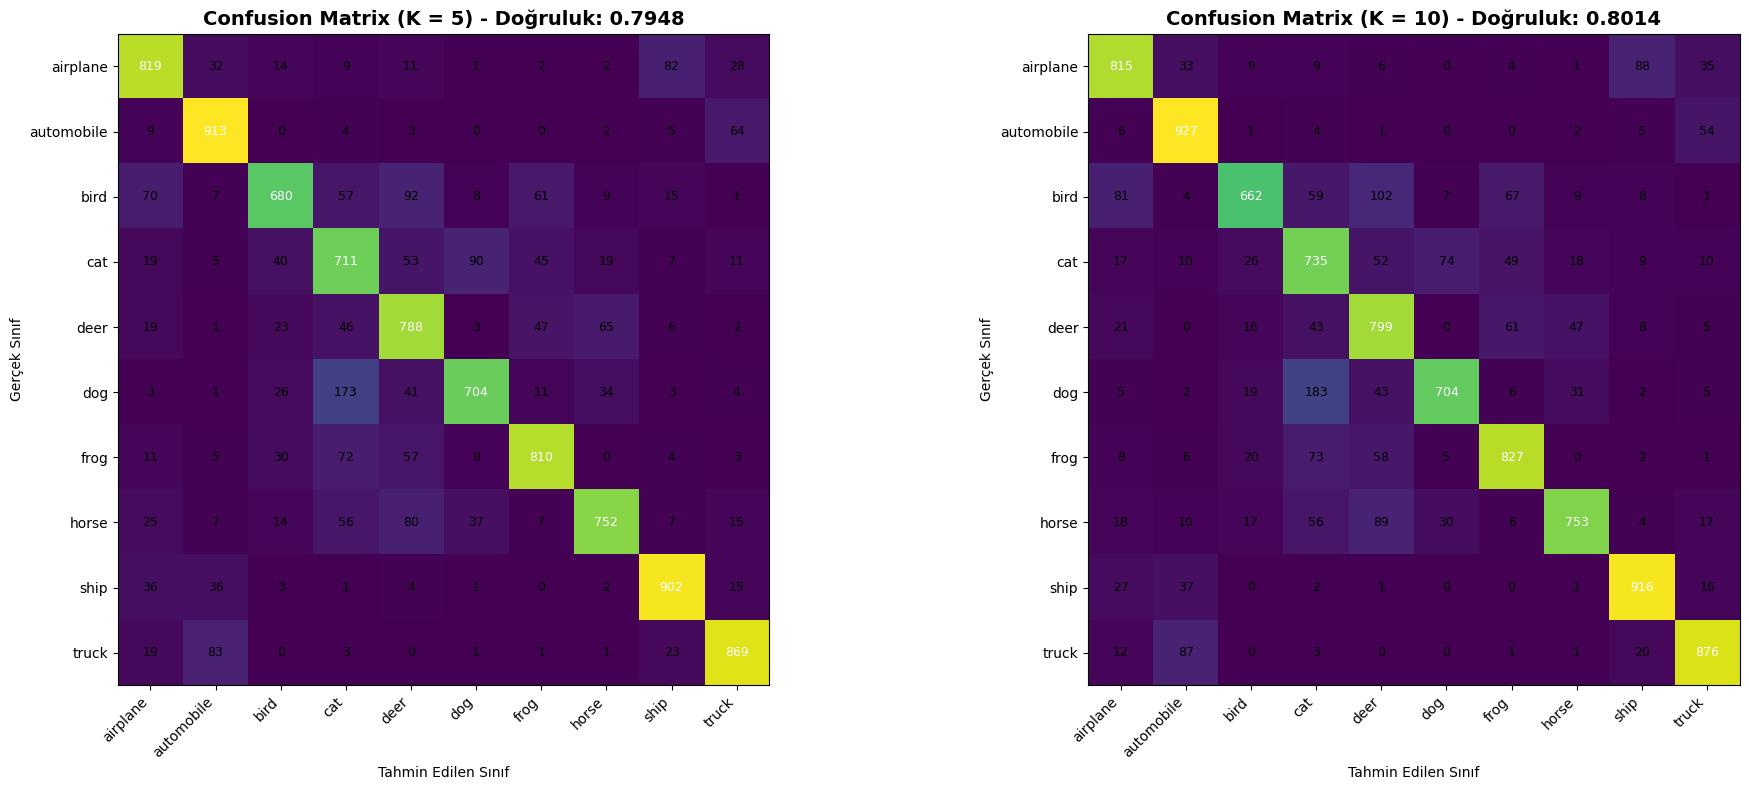

In [ ]:
# 2. K=5 ve K=10 için Confusion Matrix Yan Yana Karşılaştırması
fig, axes = plt.subplots(1, 2, figsize=(20, 8))

for i, k_val in enumerate([5, 10]):
    cm_k = confusion_matrices[k_val]
    im = axes[i].imshow(cm_k, interpolation="nearest", cmap="viridis")
    axes[i].set_title(f"Confusion Matrix (K = {k_val}) - Doğruluk: {accuracies[k_val]:.4f}", fontsize=14, fontweight='bold')
    axes[i].set_xlabel("Tahmin Edilen Sınıf")
    axes[i].set_ylabel("Gerçek Sınıf")
    axes[i].set_xticks(np.arange(10))
    axes[i].set_xticklabels(CLASS_NAMES, rotation=45, ha="right")
    axes[i].set_yticks(np.arange(10))
    axes[i].set_yticklabels(CLASS_NAMES)

    threshold = cm_k.max() / 2
    for row in range(10):
        for col in range(10):
            axes[i].text(col, row, str(cm_k[row, col]), ha="center", va="center",
                         color="white" if cm_k[row, col] > threshold else "black", fontsize=9)

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "sabit_db_k5_vs_k10_confusion_matrix.png", dpi=180)
plt.show()

## Ablasyon Çalışması: Farklı Derin Öğrenme Modellerinin CBIR Performansı

Bu bölümde ödevimize kendi model önerimizi eklemek ve farklı ağ mimarilerini karşılaştırmak için bir ablasyon çalışması yapıyoruz.
**ResNet18**, **EfficientNet_B0** ve **MobileNet_V3_Large** modellerini özellik çıkarıcı olarak kullanıp, önceden test ettiğimiz **ResNet50** ile başarım kıyaslaması yapacağız. Aynı zamanda Euclidean, Cosine ve Manhattan metriklerinin farklı modeller üzerindeki etkilerini de tablolar ve grafiklerle inceleyeceğiz.

In [ ]:
import torch.nn as nn
import torchvision.models as models
import time

def get_model_and_transform(model_name):
    """Seçilen modele göre özellik çıkarıcı ağ ve ön işleme (transform) fonksiyonunu döndürür."""
    if model_name == "ResNet18":
        weights = models.ResNet18_Weights.IMAGENET1K_V1
        model = models.resnet18(weights=weights)
        model.fc = nn.Identity() # Sınıflandırma katmanını at, sadece özellikleri al

    elif model_name == "EfficientNet_B0":
        weights = models.EfficientNet_B0_Weights.IMAGENET1K_V1
        model = models.efficientnet_b0(weights=weights)
        model.classifier = nn.Identity()

    elif model_name == "MobileNet_V3_Large":
        weights = models.MobileNet_V3_Large_Weights.IMAGENET1K_V1
        model = models.mobilenet_v3_large(weights=weights)
        model.classifier = nn.Identity()
    else:
        raise ValueError("Desteklenmeyen model!")

    model = model.to(DEVICE).eval()
    transform = weights.transforms()
    return model, transform

@torch.inference_mode()
def extract_features_for_model(base_dataset, indices, model, transform, batch_size=128):
    """Belirtilen model ve transformasyon ile özellik çıkarımı yapar."""
    ds = CIFARResized(base_dataset, indices, transform)
    loader = torch.utils.data.DataLoader(
        ds, batch_size=batch_size, shuffle=False,
        num_workers=2 if os.name != "nt" else 0,
        pin_memory=(DEVICE.type == "cuda")
    )
    all_features = []
    for batch_x, _, _ in loader:
        batch_x = batch_x.to(DEVICE)
        feats = model(batch_x).flatten(1)
        all_features.append(feats.cpu().numpy().astype(np.float32))
    return np.concatenate(all_features)

# Test edilecek modellerin listesi
ABLATION_MODELS = ["ResNet18", "EfficientNet_B0", "MobileNet_V3_Large"]

# Özellikleri saklamak için sözlükler
extracted_db_features = {"ResNet50": db_features} # Önceki kısımdan gelen ResNet50 özellikleri
extracted_query_features = {"ResNet50": query_features}

print("Modeller için özellik çıkarımı başlatılıyor...")
for m_name in ABLATION_MODELS:
    print(f"{m_name} yükleniyor ve özellikler çıkarılıyor...")
    model, transform = get_model_and_transform(m_name)

    start = time.time()
    # DB ve Query özelliklerini çıkarıyoruz (Global db_indices ve query_indices kullanılarak)
    m_db_feats = extract_features_for_model(train_ds, db_original_indices, model, transform)
    m_query_feats = extract_features_for_model(test_ds, query_original_indices, model, transform)
    elapsed = time.time() - start

    extracted_db_features[m_name] = m_db_feats
    extracted_query_features[m_name] = m_query_feats
    print(f"{m_name} tamamlandı! ({elapsed:.1f} sn) - Özellik Boyutu: {m_db_feats.shape[1]}")


Modeller için özellik çıkarımı başlatılıyor...
ResNet18 yükleniyor ve özellikler çıkarılıyor...
Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 166MB/s]


ResNet18 tamamlandı! (124.7 sn) - Özellik Boyutu: 512
EfficientNet_B0 yükleniyor ve özellikler çıkarılıyor...
Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 85.0MB/s]


EfficientNet_B0 tamamlandı! (139.9 sn) - Özellik Boyutu: 1280
MobileNet_V3_Large yükleniyor ve özellikler çıkarılıyor...
Downloading: "https://download.pytorch.org/models/mobilenet_v3_large-8738ca79.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v3_large-8738ca79.pth


100%|██████████| 21.1M/21.1M [00:00<00:00, 77.6MB/s]


MobileNet_V3_Large tamamlandı! (120.0 sn) - Özellik Boyutu: 960


### Modellerin Farklı Metriklerle Karşılaştırılması

Şimdi çıkardığımız özellik matrislerini kullanarak, `K=5` komşuluk değerinde ve farklı uzaklık metriklerinde (Euclidean, Cosine, Manhattan) mAP ve Doğruluk (Accuracy) gibi başarım skorlarını ölçeceğiz.

In [ ]:
K_EVAL = 5
metrics_to_test = ["euclidean", "cosine", "manhattan"]
model_comparison_results = []

# Karşılaştırma için küçük bir subset kullanabiliriz ya da tamamını.
# Hızlı analiz için EVAL_DB_SIZE=5000 kullanıyoruz.
COMPARE_DB = min(5000, len(db_features))

print(f"Karşılaştırma {COMPARE_DB} veritabanı görüntüsü üzerinde yapılıyor...")

for m_name in extracted_db_features.keys():
    X_db_m = extracted_db_features[m_name][:COMPARE_DB]
    y_db_m = db_y[:COMPARE_DB]
    X_q_m = extracted_query_features[m_name]

    for metric in metrics_to_test:
        p_list, r_list, f1_list, ap_list = [], [], [], []
        y_pred_m = []

        for qi in range(len(X_q_m)):
            # Sorgu yap
            order, _ = retrieve(X_q_m[qi], X_db_m, y_db_m, top_k=K_EVAL, metric=metric)
            labels_k = y_db_m[order]

            # CBIR Metrikleri
            p, r, f1, ap = retrieval_metrics(labels_k, query_y[qi], y_db_m, K_EVAL)
            p_list.append(p)
            r_list.append(r)
            f1_list.append(f1)
            ap_list.append(ap)

            # Çoğunluk oylaması (Sınıflandırma için)
            counts = np.bincount(labels_k, minlength=10)
            y_pred_m.append(np.argmax(counts))

        acc = accuracy_score(query_y, y_pred_m)

        model_comparison_results.append({
            "Model": m_name,
            "Metric": metric,
            "Precision@5": np.mean(p_list),
            "Recall@5": np.mean(r_list),
            "F1@5": np.mean(f1_list),
            "mAP@5": np.mean(ap_list),
            "Accuracy": acc
        })

model_df = pd.DataFrame(model_comparison_results)
display(model_df.round(4))
model_df.to_csv(OUTPUT_DIR / "model_ablasyon_sonuclari.csv", index=False)

Karşılaştırma 5000 veritabanı görüntüsü üzerinde yapılıyor...


,Model,Metric,Precision@5,Recall@5,F1@5,mAP@5,Accuracy
0,ResNet50,euclidean,0.7119,0.0071,0.0141,0.6517,0.7948
1,ResNet50,cosine,0.7323,0.0073,0.0145,0.6762,0.8095
2,ResNet50,manhattan,0.7140,0.0072,0.0142,0.6542,0.7915
3,ResNet18,euclidean,0.6633,0.0067,0.0132,0.5970,0.7514
4,ResNet18,cosine,0.6900,0.0069,0.0137,0.6268,0.7752
5,ResNet18,manhattan,0.6624,0.0066,0.0131,0.5960,0.7508
6,EfficientNet_B0,euclidean,0.8029,0.0080,0.0159,0.7619,0.8595
7,EfficientNet_B0,cosine,0.8017,0.0080,0.0159,0.7578,0.8624
8,EfficientNet_B0,manhattan,0.8047,0.0081,0.0160,0.7655,0.8553
9,MobileNet_V3_Large,euclidean,0.6878,0.0069,0.0136,0.6253,0.7824


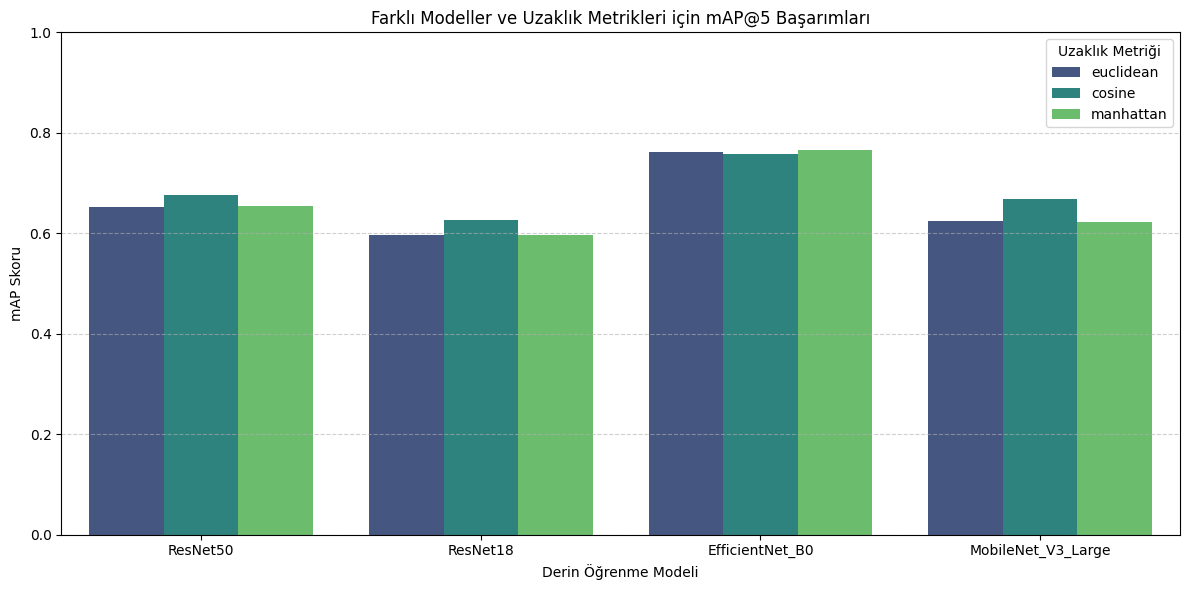

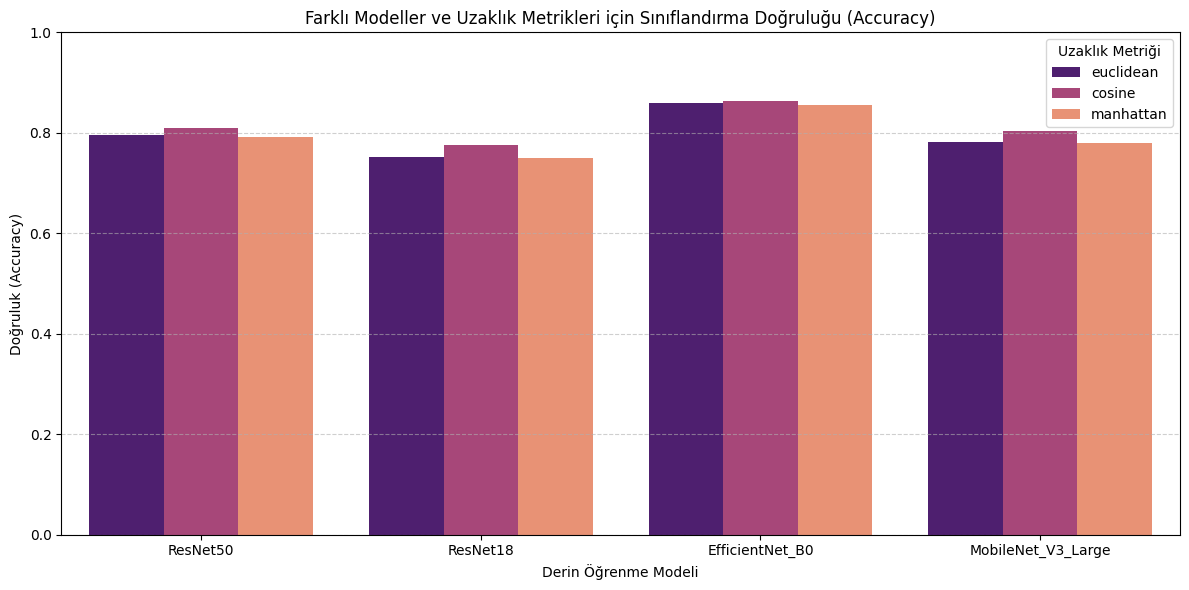

In [ ]:
# Model başarımlarını görselleştirelim
import seaborn as sns

plt.figure(figsize=(12, 6))
sns.barplot(data=model_df, x="Model", y="mAP@5", hue="Metric", palette="viridis")
plt.title("Farklı Modeller ve Uzaklık Metrikleri için mAP@5 Başarımları")
plt.ylabel("mAP Skoru")
plt.xlabel("Derin Öğrenme Modeli")
plt.ylim(0, 1.0)
plt.legend(title="Uzaklık Metriği")
plt.grid(axis='y', linestyle='--', alpha=0.6)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "ablasyon_map_karsilastirma.png", dpi=160)
plt.show()

plt.figure(figsize=(12, 6))
sns.barplot(data=model_df, x="Model", y="Accuracy", hue="Metric", palette="magma")
plt.title("Farklı Modeller ve Uzaklık Metrikleri için Sınıflandırma Doğruluğu (Accuracy)")
plt.ylabel("Doğruluk (Accuracy)")
plt.xlabel("Derin Öğrenme Modeli")
plt.ylim(0, 1.0)
plt.legend(title="Uzaklık Metriği")
plt.grid(axis='y', linestyle='--', alpha=0.6)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "ablasyon_accuracy_karsilastirma.png", dpi=160)
plt.show()

### En İyi Model İçin Confusion Matrix (Karmaşıklık Matrisi)

Tablodan elde ettiğimiz sonuçlara göre en yüksek **Accuracy (Doğruluk)** ve **mAP** skoruna sahip model ile metrik kombinasyonunu bulup, hocaya sunmak için detaylı Karmaşıklık Matrisini (Confusion Matrix) çizdiriyoruz.

En iyi sonuç EfficientNet_B0 modeli ve cosine metriği ile elde edildi. (Doğruluk: 0.8624)


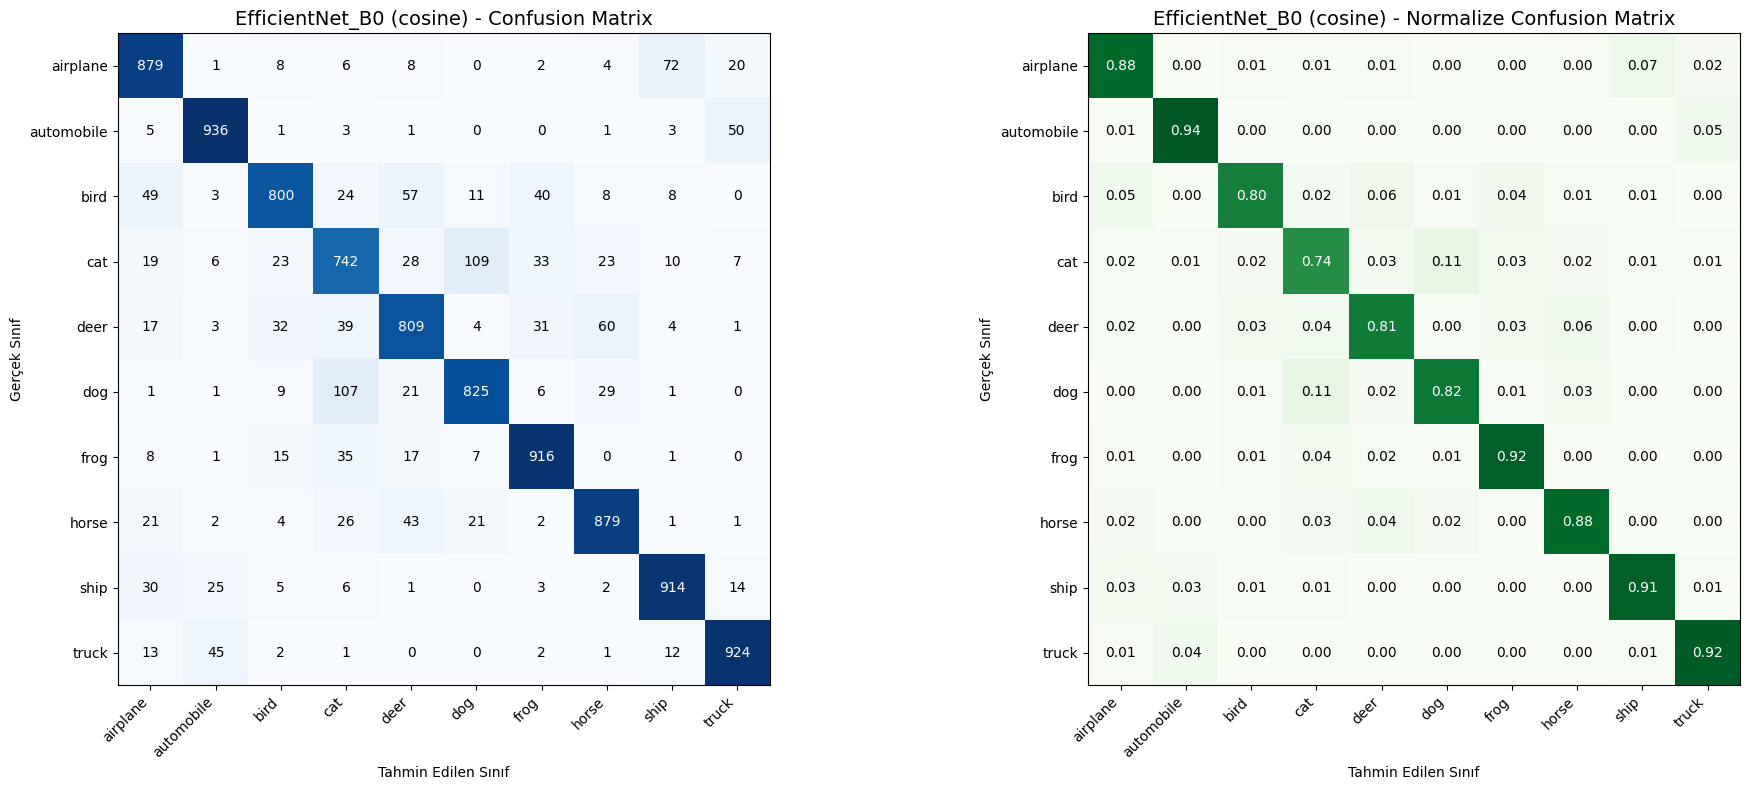

In [ ]:
# En iyi modeli otomatik seç
best_row = model_df.loc[model_df['Accuracy'].idxmax()]
best_model = best_row['Model']
best_metric = best_row['Metric']

print(f"En iyi sonuç {best_model} modeli ve {best_metric} metriği ile elde edildi. (Doğruluk: {best_row['Accuracy']:.4f})")

# En iyi model için tahminleri tekrar alıyoruz
X_db_best = extracted_db_features[best_model][:COMPARE_DB]
y_db_best = db_y[:COMPARE_DB]
X_q_best = extracted_query_features[best_model]

best_y_pred = []
for qi in range(len(X_q_best)):
    order, _ = retrieve(X_q_best[qi], X_db_best, y_db_best, top_k=5, metric=best_metric)
    counts = np.bincount(y_db_best[order], minlength=10)
    best_y_pred.append(np.argmax(counts))

best_y_pred = np.array(best_y_pred)
best_cm = confusion_matrix(query_y, best_y_pred, labels=np.arange(10))
best_cm_norm = confusion_matrix(query_y, best_y_pred, labels=np.arange(10), normalize="true")

# Görselleştirme
fig, axes = plt.subplots(1, 2, figsize=(20, 8))

# Normal CM
im1 = axes[0].imshow(best_cm, interpolation="nearest", cmap="Blues")
axes[0].set_title(f"{best_model} ({best_metric}) - Confusion Matrix", fontsize=14)
axes[0].set_xlabel("Tahmin Edilen Sınıf")
axes[0].set_ylabel("Gerçek Sınıf")
axes[0].set_xticks(np.arange(10))
axes[0].set_xticklabels(CLASS_NAMES, rotation=45, ha="right")
axes[0].set_yticks(np.arange(10))
axes[0].set_yticklabels(CLASS_NAMES)

threshold1 = best_cm.max() / 2
for i in range(10):
    for j in range(10):
        axes[0].text(j, i, str(best_cm[i, j]), ha="center", va="center",
                     color="white" if best_cm[i, j] > threshold1 else "black")

# Normalize CM
im2 = axes[1].imshow(best_cm_norm, interpolation="nearest", cmap="Greens", vmin=0, vmax=1)
axes[1].set_title(f"{best_model} ({best_metric}) - Normalize Confusion Matrix", fontsize=14)
axes[1].set_xlabel("Tahmin Edilen Sınıf")
axes[1].set_ylabel("Gerçek Sınıf")
axes[1].set_xticks(np.arange(10))
axes[1].set_xticklabels(CLASS_NAMES, rotation=45, ha="right")
axes[1].set_yticks(np.arange(10))
axes[1].set_yticklabels(CLASS_NAMES)

for i in range(10):
    for j in range(10):
        axes[1].text(j, i, f"{best_cm_norm[i, j]:.2f}", ha="center", va="center",
                     color="white" if best_cm_norm[i, j] > 0.5 else "black")

plt.tight_layout()
plt.savefig(OUTPUT_DIR / f"en_iyi_model_cm_{best_model}_{best_metric}.png", dpi=180)
plt.show()